# BudgetSwitch W2 — Pilot Study (v1.1 fixed)

**Fixes in v1.1:**
- Bug 1: `clean_catalog()` strips `_metadata` keys before passing to mode functions
- Bug 2: libnvJitLink symlink now runs in Cell 1, BEFORE any bitsandbytes/unsloth import

**Run cells IN ORDER. Do not skip Cell 1.**

In [1]:
%%bash
# Sửa đổi Cell 1: Ép link trực tiếp vào đường dẫn hệ thống của Kaggle
echo "=== Kích hoạt Hot-fix libnvJitLink ==="
LIB_SRC=$(find /usr/local/cuda-12.8/ -name "libnvJitLink.so.12" 2>/dev/null | head -1)

if [ -z "$LIB_SRC" ]; then
    echo "❌ Không tìm thấy file gốc CUDA 12.8!"
else
    # Ép liên kết mềm thẳng vào thư mục libs hệ thống công cộng
    ln -sf "$LIB_SRC" /usr/lib/x86_64-linux-gnu/libnvJitLink.so.13
    ln -sf "$LIB_SRC" /usr/local/lib/libnvJitLink.so.13
    
    # Kích hoạt ldconfig quyền cao để cập nhật bộ nạp
    ldconfig
    echo "✅ Đã vá cứng thành công liên kết libnvJitLink.so.13 hệ thống!"
fi

=== Kích hoạt Hot-fix libnvJitLink ===
✅ Đã vá cứng thành công liên kết libnvJitLink.so.13 hệ thống!


/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_loader.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm_debug.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/li

In [2]:
# Cell 2: Install dependencies (AFTER symlink fix, BEFORE any imports)
import subprocess, sys

subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y",
                "vllm", "torchvision", "torchaudio"], capture_output=True)
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                "unsloth[kaggle-new] @ git+https://github.com/unslothai/unsloth.git"],
               capture_output=True)
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                "--upgrade", "peft", "accelerate"], capture_output=True)
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                "sentence-transformers", "openai"], capture_output=True)
print("✅ Install complete")

✅ Install complete


In [3]:
# Cell 3: Imports + repo setup
import os, sys, json, time, subprocess
from pathlib import Path

REPO = Path("/kaggle/working/budgetswitch")

if not REPO.exists():
    # Dùng GITHUB_TOKEN từ Kaggle Secrets
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    
    repo_url = f"https://{token}@github.com/ductaip/budgetswitch.git"
    subprocess.run(["git", "clone", repo_url, str(REPO)], check=True)
    print("✅ Repo cloned")
else:
    # Repo đã có — pull latest
    subprocess.run(["git", "-C", str(REPO), "pull"], check=True)
    print("✅ Repo updated")

sys.path.insert(0, str(REPO))

# Load catalog
with open(REPO / "data/vitool/tool_catalog.json") as f:
    CATALOG_RAW = json.load(f)

# FIX Bug 1: strip _metadata keys
CATALOG = {k: v for k, v in CATALOG_RAW.items() if not k.startswith("_")}
print(f"✅ Catalog loaded: {len(CATALOG)} tools")

Cloning into '/kaggle/working/budgetswitch'...


✅ Repo cloned
✅ Catalog loaded: 36 tools


In [4]:
# Cell 4: Pre-compute tool embeddings (runs once, ~2 min)
import numpy as np
from modes.m2_think_search.m2_think_search import build_tool_embeddings

EMBED_PATH = "/kaggle/working/tool_embeddings.npy"

if not Path(EMBED_PATH).exists():
    print("Building tool embeddings (first time, ~2 min)...")
    # Save a clean catalog JSON for embeddings
    CLEAN_CATALOG_PATH = "/kaggle/working/tool_catalog_clean.json"
    with open(CLEAN_CATALOG_PATH, "w") as f:
        json.dump(CATALOG, f, ensure_ascii=False)
    build_tool_embeddings(CLEAN_CATALOG_PATH, EMBED_PATH)
else:
    emb = np.load(EMBED_PATH)
    print(f"✅ Loaded pre-computed embeddings: shape={emb.shape}")

Building tool embeddings (first time, ~2 min)...


W0526 08:04:10.869000 23 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W0526 08:04:10.900000 23 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

✅ Saved 36 tool embeddings to /kaggle/working/tool_embeddings.npy
   Embedding dim: 768


In [5]:
# Cell 5: Load model (NOW safe — libnvJitLink fix already applied in Cell 1)
from unsloth import FastLanguageModel
import torch

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Qwen2.5-3B-Instruct",
    max_seq_length=2048,
    load_in_4bit=True,
    fast_inference=False,   # MUST be False on Kaggle CUDA 13
    dtype=None,
)
FastLanguageModel.for_inference(model)

peak = torch.cuda.max_memory_allocated() / 1e9
print(f"✅ Model loaded. Peak VRAM: {peak:.2f} GB")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


/usr/local/lib/python3.12/dist-packages/unsloth/__init__.py:144: UserWarning: WARNING: Unsloth should be imported before [transformers, peft] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


🦥 Unsloth Zoo will now patch everything to make training faster!


<string>:1: FutureWarning: torch._dynamo.config.inline_inbuilt_nn_modules is deprecated and does not do anything, inline_inbuilt_nn_modules is always True. It will be removed in a future version of PyTorch.


==((====))==  Unsloth 2026.5.7: Fast Qwen2 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.12.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.7.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/2.36G [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

unsloth/qwen2.5-3b-instruct-unsloth-bnb-4bit does not have a padding token! Will use pad_token = <|PAD_TOKEN|>.
✅ Model loaded. Peak VRAM: 2.43 GB


In [6]:
# Cell 6: Setup retriever + LLM client
from modes.m2_think_search.m2_think_search import ToolRetriever
from openai import OpenAI

# M2 retriever (uses pre-computed embeddings — fast)
CLEAN_CATALOG_PATH = "/kaggle/working/tool_catalog_clean.json"
if not Path(CLEAN_CATALOG_PATH).exists():
    with open(CLEAN_CATALOG_PATH, "w") as f:
        json.dump(CATALOG, f, ensure_ascii=False)

retriever = ToolRetriever(
    embeddings_path=EMBED_PATH,
    catalog_path=CLEAN_CATALOG_PATH,
    embedder=None,
)
print("✅ ToolRetriever ready")

# M3 LLM client (Groq free tier)
GROQ_API_KEY = os.environ.get("GROQ_API_KEY", "REDACTED_GROQ_KEY")
if GROQ_API_KEY:
    llm_client = OpenAI(
        api_key=GROQ_API_KEY,
        base_url="https://api.groq.com/openai/v1",
    )
    print("✅ Groq client ready")
else:
    llm_client = None
    print("⚠️  No GROQ_API_KEY — M3 will be skipped")
SKIP_M3 = (llm_client is None)

✅ ToolRetriever ready
✅ Groq client ready


In [7]:
# Cell 7: Load pilot trajectories
from data.vitool.schema import load_trajectories

# Adjust path to where you uploaded vitool_pilot.jsonl
PILOT_PATH = "/kaggle/input/vitool-pilot/vitool_pilot.jsonl"
if not Path(PILOT_PATH).exists():
    PILOT_PATH = str(REPO / "data/vitool/vitool_pilot.jsonl")

trajectories = load_trajectories(PILOT_PATH)
n_steps = sum(t.num_steps for t in trajectories)
print(f"✅ Loaded {len(trajectories)} trajectories ({n_steps} steps)")

# Quick sanity check: show sample
t = trajectories[0]
print(f"\nSample: [{t.traj_id}] {t.query[:60]}")
print(f"  Steps: {[(s.expected_tool, s.difficulty.value) for s in t.steps]}")

✅ Loaded 100 trajectories (121 steps)

Sample: [banking_0009] Tôi bị mất thẻ ATM, cần khóa thẻ số 9876-5432-1098-7654 với 
  Steps: [('block_card', 'easy')]


In [8]:
# Cell 8: Quick single-step sanity check BEFORE running full simulation
# This catches any remaining bugs cheaply (no GPU needed for verifier)
from verifiers.universal.schema_verifier import verify_step_outcome
from modes.m0_fast.m0_fast import _parse_tool_call

traj = trajectories[0]
gt = traj.steps[0]
gt_dict = {"expected_tool": gt.expected_tool,
           "expected_params": gt.expected_params,
           "fuzzy_keys": gt.fuzzy_keys}

print(f"Tool to match: {gt.expected_tool}")
print(f"Expected params: {gt.expected_params}")

# Simulate what a "perfect" M0 output looks like
perfect_output = {"tool_name": gt.expected_tool, "params": gt.expected_params}
result = verify_step_outcome(perfect_output, gt_dict, CATALOG)
print(f"\n✅ Verifier sanity check: perfect output = {result} (should be True)")

# Check catalog is clean
assert all(isinstance(v, dict) for v in CATALOG.values()),     "Bug 1 still present — CATALOG contains non-dict values"
print("✅ Catalog clean — no _metadata keys")

Tool to match: block_card
Expected params: {'card_number': '9876-5432-1098-7654', 'reason': 'lost'}

✅ Verifier sanity check: perfect output = True (should be True)
✅ Catalog clean — no _metadata keys


In [9]:
# Cell 9: Run full pilot simulation
from pilot.simulate_modes import simulate_trajectories

SIM_OUT = "/kaggle/working/pilot_simulations.jsonl"
Path("/kaggle/working/pilot_results").mkdir(exist_ok=True)

print(f"Running simulation on {len(trajectories)} trajectories...")
print(f"M3 skip: {SKIP_M3}")
print("This takes ~30-60 min on T4...\n")

start = time.time()
sims = simulate_trajectories(
    trajectories=trajectories,
    tool_catalog=CATALOG,  # already clean from Cell 3
    model=model,
    tokenizer=tokenizer,
    retriever=retriever,
    llm_client=llm_client,
    skip_m3=SKIP_M3,
    output_path=SIM_OUT,
    verbose=True,
)
elapsed = time.time() - start
print(f"\n✅ Done in {elapsed/60:.1f} min. Saved to {SIM_OUT}")

# Quick success rate check
for mode in ["M0","M1","M2","M3"]:
    successes = sum(1 for s in sims if s.results[mode].success)
    print(f"  {mode}: {successes}/{len(sims)} steps succeeded ({100*successes/len(sims):.1f}%)")

Both `max_new_tokens` (=150) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Running simulation on 100 trajectories...
M3 skip: False
This takes ~30-60 min on T4...



/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API i

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-base
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Both `max_new_tokens` (=800) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=150) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=500) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://h

  Simulated 10/121 steps...


... (34 outputs left out)

Both `max_new_tokens` (=500) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=800) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=150) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [warn] M3 failed on info_retrieval_0021 step 0: Error code: 429 - {'error': {'message': 'Rate limit reached for model `llama-3.3-70b-versatile` in organization `org_01kshmf65se6ntjcnv1yp5n3we` service tier `on_demand` on tokens per day (TPD): Limit 100000, Used 99402, Requested 866. Please try again in 3m51.552s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}
  Simulated 120/121 steps...


Both `max_new_tokens` (=500) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=800) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [warn] M3 failed on info_retrieval_0021 step 1: Error code: 429 - {'error': {'message': 'Rate limit reached for model `llama-3.3-70b-versatile` in organization `org_01kshmf65se6ntjcnv1yp5n3we` service tier `on_demand` on tokens per day (TPD): Limit 100000, Used 99389, Requested 914. Please try again in 4m21.792s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}
✅ Simulated 121 steps across 100 trajectories.

✅ Done in 39.0 min. Saved to /kaggle/working/pilot_simulations.jsonl
  M0: 15/121 steps succeeded (12.4%)
  M1: 18/121 steps succeeded (14.9%)
  M2: 16/121 steps succeeded (13.2%)
  M3: 0/121 steps succeeded (0.0%)


Loaded 121 step simulations.

# Pilot Study Report

Total steps simulated: 121


## Table 1: Per-Mode Summary

| Mode | Success | Cost (units) | Avg tokens | Avg latency (ms) |
|------|---------|--------------|------------|------------------|
| M0 | 12.4% | 1 | 0 | 2435 |
| M1 | 14.9% | 3 | 168 | 8380 |
| M2 | 13.2% | 5 | 165 | 8147 |
| M3 | 0.0% | 15 | 42 | 391 |

## Decision Gate Verdict

**Hypotheses passed: 0/3**

**Overall: RED — weak support. Reconsider before GRPO (see W2 decision gate).**


### ❌ H1_overthink_easy

H1 weak: M0 easy=19%, M1 easy=22%.


### ❌ H2_underthink_hard

H2 weak: hard-step success not clearly increasing with mode cost.


### ❌ H3_allocation_gap

H3 weak: oracle does not clearly beat fixed-M1 on the frontier.


### Notes
- Check task difficulty distribution; may need more multi-step/hard tasks.
- Consider Fallback 2 (empirical study) if gap genuinely absent.

✅ Report saved to /kaggle/working/pilot_results/pilot_report.md
✅ Saved heatmap to pilot/results/f

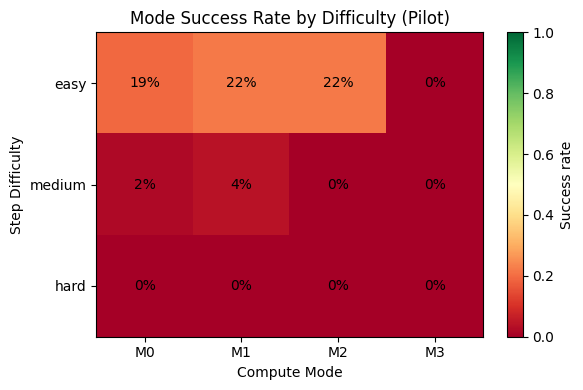

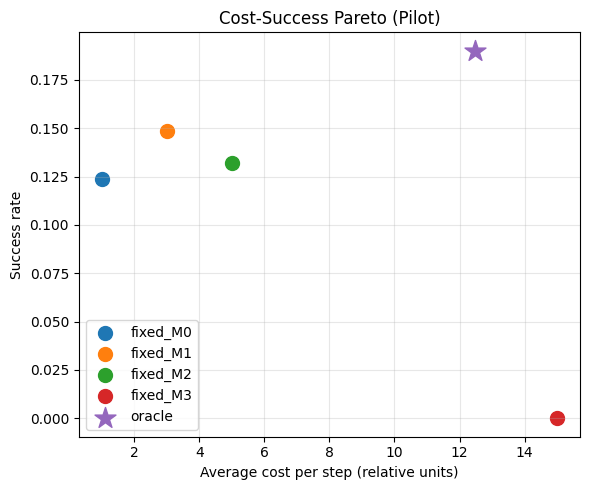

In [10]:
# Cell 10: Run pilot analysis + Decision Gate
from pilot.analyze_pilot import generate_report

verdict = generate_report(
    sim_path=SIM_OUT,
    report_path="/kaggle/working/pilot_results/pilot_report.md",
)

print("\n" + "="*55)
print("DECISION GATE VERDICT")
print("="*55)
print(verdict["overall"])
print(f"Hypotheses passed: {verdict['hypotheses_passed']}")
for hname, h in verdict["hypotheses"].items():
    icon = "✅" if h["pass"] else "❌"
    print(f"  {icon} {hname}")
    print(f"     {h['interpretation']}")

## What to do next

**GREEN (3/3):** Proceed to W3 — constrained decoding + cold-start SFT.

**YELLOW (2/3):** Proceed but note which hypothesis failed. 
May need more hard/multi-step tasks or drop one mode.

**RED (<2/3):** Before continuing, check:
1. Run Cell 9 success rates — are they all 0%? → verifier bug
2. Are all 100 trajectories easy/single-step? → add harder tasks  
3. Is M0 already ≥85% on everything? → tasks too easy for pilot

**Download these outputs and push to repo:**
- `/kaggle/working/pilot_results/pilot_report.md`
- `/kaggle/working/pilot_results/fig1_heatmap.png`
- `/kaggle/working/pilot_results/fig2_pareto.png`
- `/kaggle/working/pilot_simulations.jsonl`